# LAB 01 — The Financial Crisis and the Regulatory Maze
## Engineering context with an Obsidian-compatible regulatory knowledge graph

**Second Brain: Engineering Context for Intelligent Decisions**  
**Laboratory 1 of 4 · Regulatory intelligence · 10 executable code cells**

> **Research question.** Can an auditable, typed knowledge graph improve the completeness, traceability, and legal consistency of an LLM-assisted regulatory response, compared with ordinary prompting and document retrieval?

**Scope and legal disclaimer.** This is an educational simulation, not legal advice. Every statute, article, regulatory circular, judicial decision, competence allocation, and quotation in the executable corpus is **synthetic**. The scenario is inspired by the complexity of financial-sector regulation, but it does not reproduce, interpret, or claim to state current Mexican law. Real legal deployment requires authenticated primary sources, effective-date validation, counsel review, and a documented authority chain.

**Execution:** Google Colab or local Python 3.10+. The notebook constructs a Markdown vault, builds a typed graph, injects a payment-system shock, compares four context strategies, optionally asks **Claude Haiku 5.5** to produce a bounded judgment, evaluates evidence coverage, and exports an Obsidian-compatible ZIP. The API key is read from the Colab Secrets entry `ANTHROPIC_API_KEY`; no secret is written to disk.

---

## Introduction — Knowledge as an architecture of institutional judgment

A regulator confronting a financial disturbance does not operate in a world of isolated documents. The authority to act may be established in a primary statute, circumscribed by another statute, operationalized in a secondary rule, interpreted by a court, and qualified by the timing of an administrative decision. Each document is potentially relevant, yet relevance alone does not establish a legally permissible course of action. The central challenge is therefore not merely information retrieval. It is the reconstruction of a system of relationships among authorities, duties, constraints, institutional actors, factual events, and proposed interventions.

Large language models offer a powerful conversational interface to this problem. They can summarize long texts, compare alternatives, draft memoranda, and expose ambiguities in policy design. However, the quality of their conclusions depends on the evidence they are given and on whether the evidence preserves the structure of the underlying legal problem. A conventional prompt may omit a crucial exception. A long-context prompt may contain all necessary documents but fail to direct attention to a cross-reference. A vector retrieval system may retrieve passages with similar language while missing a decisive relationship expressed through a different vocabulary. None of these limitations implies that language models cannot reason. They suggest that context construction is itself an engineering problem worthy of explicit treatment.

This laboratory develops a small, transparent Second Brain for regulatory analysis. The knowledge base is organized as an Obsidian-compatible Markdown vault: each note is a human-readable object, and links connect statutes, rules, judicial interpretations, agencies, events, and policy options. Frontmatter provides stable identifiers, document types, effective dates, and source classifications. A separate typed-edge ledger gives each connection a defined meaning, such as authorizes, constrains, implements, interprets, supervises, or conflicts_with. The result is simultaneously legible to a human analyst and usable by a graph algorithm.

The distinction between a Markdown graph and a formal knowledge graph matters. Two notes linked by a wikilink may be associated in any number of ways. A legal reasoning system must distinguish a source that creates power from one that limits power, and a source that is binding from one that is merely explanatory. Typed edges are therefore not decorative metadata. They carry the semantics required for defensible traversal, conflict detection, and evidence assembly. Likewise, source provenance is not a citation added after reasoning is complete. It is part of the data model that determines what claims may responsibly be made.

Our case concerns a fictional payment intermediary, MeridianPay, whose settlement operations are disrupted during a period of market stress. Banks, merchants, securities intermediaries, and payment users are exposed to operational delays and liquidity pressures. A financial stability committee asks for a narrowly tailored emergency response that contains propagation without exceeding delegated authority. The committee cannot simply amend every statute or suspend all obligations. It must identify which actions are administratively available, which require further legal authorization, and which would conflict with higher-order constraints. This gives the exercise a clear decision mandate and a natural need for cross-document reasoning.

We intentionally use a synthetic corpus. The point is to demonstrate architecture and evaluation, not to manufacture authoritative statements about existing legislation. Synthetic documents permit us to create known dependencies, deliberately ambiguous clauses, and a hidden constraint against which different context strategies can be assessed. The notebook will label all generated notes as synthetic and will never present the simulation as a current-law opinion. A later research-grade version could ingest authenticated legislation, secondary regulation, and judicial decisions under a much stricter provenance and temporal-validity workflow.

Four experimental conditions share the same corpus and problem. The first receives only the crisis description and a generic instruction. The second receives a broad concatenated document package. The third uses lexical and TF-IDF retrieval as a lightweight stand-in for a conventional passage-retrieval baseline. The fourth assembles a targeted context package by traversing typed relationships from the event and proposed intervention. The comparison is not constructed to guarantee victory for graph methods. A well-prepared long-context package can perform strongly, while a poorly maintained graph can miss evidence or amplify erroneous connections. The experiment instead asks which architecture retrieves the decisive facts with the least irrelevant material and the clearest audit trail.

The judgment layer uses Claude Haiku 5.5 when the user has configured an Anthropic API key. Its role is explicitly bounded: analyze the supplied synthetic evidence, identify legal obstacles, recommend a cautious intervention, and cite note identifiers. The notebook avoids a zero-temperature setting, does not rely on provider-enforced JSON schemas, constrains response length, and includes robust extraction and parsing. If the API is unavailable, the pipeline remains runnable through deterministic evidence-based diagnostics, which are clearly identified as diagnostics rather than fabricated model responses.

Finally, the laboratory treats institutional intelligence as a feedback system. A useful Second Brain must make it possible to update a source, invalidate a stale edge, reproduce a context package, and explain why a recommendation changed. The output is therefore more than a single answer: it includes the vault, graph ledger, scenario, assembled evidence, evaluation metrics, and a decision memorandum. Students should leave understanding that knowledge engineering is not a substitute for judgment. It is the architecture that makes judgment more informed, contestable, and accountable.

The ten code cells proceed from environment preparation to corpus construction, graph validation, crisis propagation, retrieval baselines, graph-aware context assembly, bounded model judgment, and export. Each is preceded by a detailed conceptual explanation. Run the cells in order for the first pass; after that, change one synthetic rule or relationship and observe how the graph, context package, and recommendation respond. That controlled intervention is the most important experiment in the notebook.

The design also anticipates governance questions that become more important as the corpus grows. Who is allowed to add an edge that asserts legal authority? How should disputed interpretations be represented without prematurely resolving them? What happens when a regulation is amended, superseded, or suspended? A production Second Brain would require versioned source snapshots, explicit reviewers, approval states, and temporal graph queries. The present notebook implements only the foundation, but these questions guide the schema and motivate the later exercises. They also explain why the laboratory treats a graph as a governed evidence structure rather than a visualization alone.

## 01 · Environment, reproducibility, and secrets

A rigorous laboratory begins by separating what must be reproducible from what may depend on external services. The deterministic components of this notebook—synthetic source generation, note serialization, graph construction, path discovery, evidence scoring, and export—must run without an API key. Only the optional judgment engine depends on an external model. This separation prevents an authentication problem from being confused with a knowledge-architecture problem. It also permits students to inspect every intermediate representation before inviting a model to synthesize an answer.

The first cell establishes a stable workspace under the Colab runtime, installs lightweight dependencies if necessary, and sets a fixed random seed. We use Python dictionaries and data frames for structured records, NetworkX for graph operations, and scikit-learn for a transparent retrieval baseline. None of these components requires a proprietary vector database. This is deliberate: our first goal is conceptual clarity, not infrastructure complexity. Obsidian itself is not installed inside Colab; instead, we produce the Markdown and wikilink conventions that Obsidian reads directly.

The model key must be retrieved from Google Colab Secrets, using the exact uppercase name ANTHROPIC_API_KEY. We do not ask the student to paste a secret into a code cell, place it in notebook metadata, or save it in an exported file. The cell checks for the key and reports only whether it is available. It also supports a local environment variable for non-Colab execution, without printing the value. Claude is optional because an educational notebook must remain inspectable even when external connectivity, credits, or permissions are unavailable.

Finally, we define a model identifier for Claude Haiku 5.5. The live API call will omit the optional temperature argument. We will not request a strict JSON response format from the provider; later we will request ordinary text with identifiable headings and parse it defensively. This design directly addresses two practical fragilities: models may return unexpected wrappers around structured answers, and excessively ambitious response lengths may lead to truncated outputs. The result of this first cell is an environment report and a directory tree, not an analytical conclusion.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import sys, subprocess, importlib.util, os, random, pathlib
for package, module in [("networkx","networkx"),("pandas","pandas"),("scikit-learn","sklearn"),("matplotlib","matplotlib")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable,"-m","pip","-q","install",package])
import pandas as pd, networkx as nx, matplotlib.pyplot as plt
from IPython.display import display
SEED=766; random.seed(SEED)
ROOT=pathlib.Path('/content/drive/MyDrive/Colab Notebooks/TOPIC_788 SECOND BRAIN PROJECT LAB 01')
VAULT=ROOT/'Vault'; NOTES=VAULT/'Notes'; OUT=ROOT/'outputs'
for p in (NOTES,OUT): p.mkdir(parents=True,exist_ok=True)
try:
    from google.colab import userdata
    API_KEY=userdata.get('ANTHROPIC_API_KEY')
except Exception:
    API_KEY=os.environ.get('ANTHROPIC_API_KEY')
MODEL='claude-haiku-5-5'; TEMPERATURE=0.2; MAX_TOKENS=1100
print({'workspace':str(ROOT),'model':MODEL,'key_available':bool(API_KEY),'seed':SEED})

{'workspace': '/content/drive/MyDrive/Colab Notebooks/TOPIC_788 SECOND BRAIN PROJECT LAB 01', 'model': 'claude-haiku-5-5', 'key_available': True, 'seed': 766}


## 02 · Build a synthetic legal corpus

We now move from computational infrastructure to legal information design. A knowledge graph cannot repair an incoherent corpus. Each source must have an identity, a document class, a short text, a provenance label, and a time interval within which it is considered applicable. The second cell creates a deliberately small but interdependent fictional legal environment. Its sources include framework statutes, an operational circular, a supervisory directive, an interpretive judicial note, and a tax-related constraint. It also defines institutions, the payment intermediary, and candidate emergency measures.

Every record is explicitly marked SYNTHETIC. The use of familiar financial-sector concepts does not imply that the fictional clauses reproduce any Mexican statute. We do not quote actual articles or invent authentic case numbers. Instead, the documents encode testable relationships: a payments statute permits a temporary settlement safeguard; a banking statute requires coordination before imposing certain obligations on banks; a higher-level constraint prohibits blanket confiscation of customer balances; and a judicial interpretation requires proportionality and a time limit. These distinctions make it possible to evaluate whether a context-building method finds both enabling authority and legal limitations.

The scenario also contains a deliberately tempting intervention: freezing all customer balances. This is attractive as a crude containment mechanism but is prohibited by one of the synthetic constraints. A second intervention—time-limited enhanced settlement monitoring with safeguarded customer access—is more narrowly tailored. Students should understand that the experiment is not about choosing a predetermined policy because the instructor says so. It is about whether the architecture delivers the evidence needed to distinguish interventions and whether the decision memo can explain its reasoning.

We use stable identifiers rather than document titles as primary keys. Titles may change, while identifiers anchor citations and graph edges. The cell prints a compact inventory so that the class distribution and provenance of the corpus can be inspected. Later, the same schema can be expanded to hundreds of notes or replaced with authenticated materials. What matters now is that each claim has a home, each note has an identity, and the corpus contains genuine cross-document dependencies.

In [ ]:
import pandas as pd
from datetime import date
SYN='SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW'
raw=[
('LAW_PAY','statute','Fictional Payments Stability Act','Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.'),
('LAW_BANK','statute','Fictional Banking Coordination Act','Emergency obligations imposed on participating banks require prior consultation with the banking supervisor and a written coordination record.'),
('LAW_MARKET','statute','Fictional Securities Intermediaries Act','Securities intermediaries must preserve client-asset segregation and report material settlement exposure to the market supervisor.'),
('LAW_TAX','statute','Fictional Transaction Tax Continuity Act','Emergency payment controls do not suspend applicable tax reporting or authorize diversion of segregated customer funds.'),
('LAW_CENTRAL','statute','Fictional Central Bank Operations Act','The central bank may issue operational settlement instructions within its delegated mandate, but may not confiscate customer balances.'),
('RULE_SETTLE','secondary_rule','Fictional Settlement Continuity Rule','Enhanced monitoring and limited settlement safeguards require daily reporting, an expiration date, and public notice of customer-access protections.'),
('CIRC_REPORT','circular','Fictional Supervisory Circular 7','Affected banks and payment intermediaries must submit intraday liquidity and failed-settlement reports to their competent supervisors.'),
('CASE_PROP','judicial_interpretation','Fictional Proportionality Decision','An emergency restriction must be necessary, time-limited, reviewable, and no broader than needed to address the identified disruption.'),
('OPINION_FREEZE','interpretive_note','Fictional Customer Access Opinion','A blanket freeze of all customer balances conflicts with the customer-access safeguard and exceeds delegated operational authority.'),
('AGENCY_CB','institution','Fictional Central Bank','Competent authority for operational settlement continuity within the simulated legal framework.'),
('AGENCY_BANK','institution','Fictional Banking Supervisor','Competent supervisor for prudential obligations imposed on participating banks.'),
('MERIDIAN','entity','MeridianPay','Fictional payment intermediary affected by the simulated settlement incident.'),
('EVENT_CRISIS','event','MeridianPay Settlement Disruption','Synthetic settlement outage creates delayed payments and intraday liquidity pressures.'),
('OPTION_FREEZE','intervention','Blanket Balance Freeze','Candidate measure: freeze all customer balances across affected intermediaries.'),
('OPTION_MONITOR','intervention','Time-Limited Enhanced Monitoring','Candidate measure: 14-day monitoring, targeted settlement safeguard, daily reporting, and preserved customer access.'),
('OPTION_REPORT','intervention','Reporting-Only Response','Candidate measure: increase reporting but impose no temporary settlement safeguard.')]
records={i:{'id':i,'kind':kind,'title':title,'text':body,'provenance':SYN,'effective_from':'2026-01-01','effective_to':None} for i,kind,title,body in raw}
critical={'LAW_PAY','LAW_BANK','LAW_CENTRAL','RULE_SETTLE','CASE_PROP','OPINION_FREEZE'}
display(pd.DataFrame(records.values())[['id','kind','title']]); print('Critical evidence identifiers:',sorted(critical))

,id,kind,title
0,LAW_PAY,statute,Fictional Payments Stability Act
1,LAW_BANK,statute,Fictional Banking Coordination Act
2,LAW_MARKET,statute,Fictional Securities Intermediaries Act
3,LAW_TAX,statute,Fictional Transaction Tax Continuity Act
4,LAW_CENTRAL,statute,Fictional Central Bank Operations Act
5,RULE_SETTLE,secondary_rule,Fictional Settlement Continuity Rule
6,CIRC_REPORT,circular,Fictional Supervisory Circular 7
7,CASE_PROP,judicial_interpretation,Fictional Proportionality Decision
8,OPINION_FREEZE,interpretive_note,Fictional Customer Access Opinion
9,AGENCY_CB,institution,Fictional Central Bank


Critical evidence identifiers: ['CASE_PROP', 'LAW_BANK', 'LAW_CENTRAL', 'LAW_PAY', 'OPINION_FREEZE', 'RULE_SETTLE']


## 03 · Materialize the Obsidian Markdown vault

An Obsidian vault is simply a directory of Markdown files that obey recognizable conventions. This simplicity is one of its pedagogical advantages. Students can inspect a note with any text editor, search it with standard tools, and visualize its relationships in Obsidian without converting the corpus into an opaque proprietary format. The third cell serializes the synthetic source records into Markdown files with YAML frontmatter and explicit wikilinks. It also writes a README note explaining the educational status of the corpus and how to navigate the vault.

We keep the note body readable. A document begins with a descriptive heading, its synthetic legal text, a section listing related notes, and a clear provenance warning. The frontmatter includes identifiers, source class, synthetic status, and effective-date fields. The wikilinks make the vault navigable, but they are not treated as sufficient proof of legal meaning. The edge ledger constructed in the next cell will state precisely whether one source authorizes, constrains, interprets, or implements another. This two-layer design—human-readable links plus machine-readable predicates—prevents a common conceptual error: treating visual proximity in an Obsidian graph as evidence of legal authority.

The cell also creates a simple index note that links to all sources. This ensures that a student opening the vault for the first time has a stable starting point. The file layout uses a single Notes directory to avoid accidental broken links and to keep the first laboratory manageable. More sophisticated vaults may separate Sources, Actors, Events, Claims, and Decisions into folders, but folder hierarchy is not the essence of a knowledge graph. Typed connections and provenance matter more than where a file is stored.

An important implementation detail is deterministic regeneration. Rerunning the cell should overwrite the generated synthetic notes consistently, without duplicating them or accumulating stale versions. This is valuable in teaching because students will deliberately modify assumptions and compare outputs. At the end, the cell displays one complete note, allowing a direct check of the frontmatter, prose, and links. The expected artifact is a usable Obsidian vault rather than a screenshot of a graph.

In [ ]:
import pathlib
import json

# Ensure context is established
SYN = 'SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW'
raw = [
    ('LAW_PAY','statute','Fictional Payments Stability Act','Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.'),
    ('LAW_BANK','statute','Fictional Banking Coordination Act','Emergency obligations imposed on participating banks require prior consultation with the banking supervisor and a written coordination record.'),
    ('LAW_MARKET','statute','Fictional Securities Intermediaries Act','Securities intermediaries must preserve client-asset segregation and report material settlement exposure to the market supervisor.'),
    ('LAW_TAX','statute','Fictional Transaction Tax Continuity Act','Emergency payment controls do not suspend applicable tax reporting or authorize diversion of segregated customer funds.'),
    ('LAW_CENTRAL','statute','Fictional Central Bank Operations Act','The central bank may issue operational settlement instructions within its delegated mandate, but may not confiscate customer balances.'),
    ('RULE_SETTLE','secondary_rule','Fictional Settlement Continuity Rule','Enhanced monitoring and limited settlement safeguards require daily reporting, an expiration date, and public notice of customer-access protections.'),
    ('CIRC_REPORT','circular','Fictional Supervisory Circular 7','Affected banks and payment intermediaries must submit intraday liquidity and failed-settlement reports to their competent supervisors.'),
    ('CASE_PROP','judicial_interpretation','Fictional Proportionality Decision','An emergency restriction must be necessary, time-limited, reviewable, and no broader than needed to address the identified disruption.'),
    ('OPINION_FREEZE','interpretive_note','Fictional Customer Access Opinion','A blanket freeze of all customer balances conflicts with the customer-access safeguard and exceeds delegated operational authority.'),
    ('AGENCY_CB','institution','Fictional Central Bank','Competent authority for operational settlement continuity within the simulated legal framework.'),
    ('AGENCY_BANK','institution','Fictional Banking Supervisor','Competent supervisor for prudential obligations imposed on participating banks.'),
    ('MERIDIAN','entity','MeridianPay','Fictional payment intermediary affected by the simulated settlement incident.'),
    ('EVENT_CRISIS','event','MeridianPay Settlement Disruption','Synthetic settlement outage creates delayed payments and intraday liquidity pressures.'),
    ('OPTION_FREEZE','intervention','Blanket Balance Freeze','Candidate measure: freeze all customer balances across affected intermediaries.'),
    ('OPTION_MONITOR','intervention','Time-Limited Enhanced Monitoring','Candidate measure: 14-day monitoring, targeted settlement safeguard, daily reporting, and preserved customer access.'),
    ('OPTION_REPORT','intervention','Reporting-Only Response','Candidate measure: increase reporting but impose no temporary settlement safeguard.')
]
records = {i: {'id': i, 'kind': kind, 'title': title, 'text': body, 'provenance': SYN, 'effective_from': '2026-01-01', 'effective_to': None} for i, kind, title, body in raw}

edges = [
    ('LAW_PAY','RULE_SETTLE','authorizes'),('LAW_CENTRAL','RULE_SETTLE','authorizes'),
    ('LAW_BANK','CIRC_REPORT','authorizes'),('RULE_SETTLE','CIRC_REPORT','implements'),
    ('CASE_PROP','RULE_SETTLE','constrains'),('LAW_CENTRAL','OPTION_FREEZE','constrains'),
    ('OPINION_FREEZE','OPTION_FREEZE','conflicts_with'),('LAW_TAX','OPTION_FREEZE','constrains'),
    ('LAW_MARKET','OPTION_FREEZE','constrains'),('RULE_SETTLE','OPTION_MONITOR','authorizes'),
    ('CASE_PROP','OPTION_MONITOR','constrains'),('LAW_BANK','OPTION_MONITOR','constrains'),
    ('AGENCY_CB','RULE_SETTLE','supervises'),('AGENCY_BANK','CIRC_REPORT','supervises'),
    ('EVENT_CRISIS','MERIDIAN','applies_to'),('EVENT_CRISIS','OPTION_MONITOR','triggered_by'),
    ('EVENT_CRISIS','OPTION_FREEZE','triggered_by'),('EVENT_CRISIS','OPTION_REPORT','triggered_by'),
    ('EVENT_CRISIS','LAW_PAY','applies_to'),('EVENT_CRISIS','LAW_BANK','applies_to'),
    ('OPTION_MONITOR','RULE_SETTLE','applies_to'),('OPTION_FREEZE','OPINION_FREEZE','conflicts_with'),
    ('OPTION_MONITOR','LAW_CENTRAL','applies_to'),('OPTION_MONITOR','CASE_PROP','applies_to'),
    ('OPTION_MONITOR','CIRC_REPORT','applies_to'),('OPINION_FREEZE','LAW_CENTRAL','interprets')
]

links = {i: set() for i in records}
for a, b, p in edges:
    links[a].add(b)
    links[b].add(a)

def note_text(r):
    front = {
        'id': r['id'],
        'type': r['kind'],
        'synthetic': True,
        'effective_from': r['effective_from'],
        'effective_to': r['effective_to'] or 'null'
    }
    front_str = '\n'.join(f"{k}: {str(v).lower() if isinstance(v, bool) else v}" for k, v in front.items())
    header = f"---\n{front_str}\n---\n"
    return header + f"\n# {r['title']}\n\n> {SYN}\n\n## Text\n{r['text']}\n\n## Linked notes\n" + '\n'.join(f"- [[{x}]]" for x in sorted(links[r['id']])) + '\n'

ROOT = pathlib.Path('/content/drive/MyDrive/Colab Notebooks/TOPIC_788 SECOND BRAIN PROJECT LAB 01')
VAULT = ROOT/'Vault'
NOTES = VAULT/'Notes'
NOTES.mkdir(parents=True, exist_ok=True)

for r in records.values():
    (NOTES/(r['id']+'.md')).write_text(note_text(r), encoding='utf-8')

(VAULT/'START_HERE.md').write_text(
    '# Laboratory 01 — Synthetic Regulatory Knowledge Vault\n\n**All sources are fictional and educational.**\n\n' +
    '\n'.join(f"- [[{i}]] — {r['title']}" for i, r in records.items()),
    encoding='utf-8'
)

print((NOTES/'LAW_PAY.md').read_text()[:900])
print('Notes created:', len(list(NOTES.glob('*.md'))))

---
id: LAW_PAY
type: statute
synthetic: true
effective_from: 2026-01-01
effective_to: null
---

# Fictional Payments Stability Act

> SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW

## Text
Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.

## Linked notes
- [[EVENT_CRISIS]]
- [[RULE_SETTLE]]

Notes created: 16


In [ ]:
import json
# Re-establishing records context to ensure cell independence
SYN='SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW'
raw=[
('LAW_PAY','statute','Fictional Payments Stability Act','Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.'),
('LAW_BANK','statute','Fictional Banking Coordination Act','Emergency obligations imposed on participating banks require prior consultation with the banking supervisor and a written coordination record.'),
('LAW_MARKET','statute','Fictional Securities Intermediaries Act','Securities intermediaries must preserve client-asset segregation and report material settlement exposure to the market supervisor.'),
('LAW_TAX','statute','Fictional Transaction Tax Continuity Act','Emergency payment controls do not suspend applicable tax reporting or authorize diversion of segregated customer funds.'),
('LAW_CENTRAL','statute','Fictional Central Bank Operations Act','The central bank may issue operational settlement instructions within its delegated mandate, but may not confiscate customer balances.'),
('RULE_SETTLE','secondary_rule','Fictional Settlement Continuity Rule','Enhanced monitoring and limited settlement safeguards require daily reporting, an expiration date, and public notice of customer-access protections.'),
('CIRC_REPORT','circular','Fictional Supervisory Circular 7','Affected banks and payment intermediaries must submit intraday liquidity and failed-settlement reports to their competent supervisors.'),
('CASE_PROP','judicial_interpretation','Fictional Proportionality Decision','An emergency restriction must be necessary, time-limited, reviewable, and no broader than needed to address the identified disruption.'),
('OPINION_FREEZE','interpretive_note','Fictional Customer Access Opinion','A blanket freeze of all customer balances conflicts with the customer-access safeguard and exceeds delegated operational authority.'),
('AGENCY_CB','institution','Fictional Central Bank','Competent authority for operational settlement continuity within the simulated legal framework.'),
('AGENCY_BANK','institution','Fictional Banking Supervisor','Competent supervisor for prudential obligations imposed on participating banks.'),
('MERIDIAN','entity','MeridianPay','Fictional payment intermediary affected by the simulated settlement incident.'),
('EVENT_CRISIS','event','MeridianPay Settlement Disruption','Synthetic settlement outage creates delayed payments and intraday liquidity pressures.'),
('OPTION_FREEZE','intervention','Blanket Balance Freeze','Candidate measure: freeze all customer balances across affected intermediaries.'),
('OPTION_MONITOR','intervention','Time-Limited Enhanced Monitoring','Candidate measure: 14-day monitoring, targeted settlement safeguard, daily reporting, and preserved customer access.'),
('OPTION_REPORT','intervention','Reporting-Only Response','Candidate measure: increase reporting but impose no temporary settlement safeguard.')]
records={i:{'id':i,'kind':kind,'title':title,'text':body,'provenance':SYN,'effective_from':'2026-01-01','effective_to':None} for i,kind,title,body in raw}

edges=[
('LAW_PAY','RULE_SETTLE','authorizes'),('LAW_CENTRAL','RULE_SETTLE','authorizes'),
('LAW_BANK','CIRC_REPORT','authorizes'),('RULE_SETTLE','CIRC_REPORT','implements'),
('CASE_PROP','RULE_SETTLE','constrains'),('LAW_CENTRAL','OPTION_FREEZE','constrains'),
('OPINION_FREEZE','OPTION_FREEZE','conflicts_with'),('LAW_TAX','OPTION_FREEZE','constrains'),
('LAW_MARKET','OPTION_FREEZE','constrains'),('RULE_SETTLE','OPTION_MONITOR','authorizes'),
('CASE_PROP','OPTION_MONITOR','constrains'),('LAW_BANK','OPTION_MONITOR','constrains'),
('AGENCY_CB','RULE_SETTLE','supervises'),('AGENCY_BANK','CIRC_REPORT','supervises'),
('EVENT_CRISIS','MERIDIAN','applies_to'),('EVENT_CRISIS','OPTION_MONITOR','triggered_by'),
('EVENT_CRISIS','OPTION_FREEZE','triggered_by'),('EVENT_CRISIS','OPTION_REPORT','triggered_by'),
('EVENT_CRISIS','LAW_PAY','applies_to'),('EVENT_CRISIS','LAW_BANK','applies_to'),
('OPTION_MONITOR','RULE_SETTLE','applies_to'),('OPTION_FREEZE','OPINION_FREEZE','conflicts_with'),
('OPTION_MONITOR','LAW_CENTRAL','applies_to'),('OPTION_MONITOR','CASE_PROP','applies_to'),
('OPTION_MONITOR','CIRC_REPORT','applies_to'),('OPINION_FREEZE','LAW_CENTRAL','interprets')]
links={i:set() for i in records}
for a,b,p in edges: links[a].add(b);links[b].add(a)
def note_text(r):
    front={'id':r['id'],'type':r['kind'],'synthetic':True,'effective_from':r['effective_from'],'effective_to':r['effective_to'] or 'null'}
    header='---\n'+'\n'.join(f'{k}: {str(v).lower() if isinstance(v,bool) else v}' for k,v in front.items())+'\n---\n'
    return header+f"\n# {r['title']}\n\n> {SYN}\n\n## Text\n{r['text']}\n\n## Linked notes\n"+'\n'.join(f'- [[{x}]]' for x in sorted(links[r['id']]))+'\n'
for r in records.values(): (NOTES/(r['id']+'.md')).write_text(note_text(r),encoding='utf-8')
(VAULT/'START_HERE.md').write_text('# Laboratory 01 — Synthetic Regulatory Knowledge Vault\n\n**All sources are fictional and educational.**\n\n'+'\n'.join(f'- [[{i}]] — {r["title"]}' for i,r in records.items()),encoding='utf-8')
print((NOTES/'LAW_PAY.md').read_text()[:900]);print('Notes created:',len(list(NOTES.glob('*.md'))))

---
id: LAW_PAY
type: statute
synthetic: true
effective_from: 2026-01-01
effective_to: null
---

# Fictional Payments Stability Act

> SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW

## Text
Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.

## Linked notes
- [[EVENT_CRISIS]]
- [[RULE_SETTLE]]

Notes created: 16


## 04 · Construct and validate a typed regulatory graph

The fourth cell converts our records into a graph that can support computational reasoning. Each note becomes a node with its document class and provenance. Each edge is a relationship with a predicate and a brief justification. We use a directed multigraph because the same two entities can have more than one legally meaningful relationship. A rule may both implement a statute and be constrained by a judicial interpretation. Collapsing these relationships into a single unlabeled line would destroy information required for legal analysis.

Our vocabulary of predicates is deliberately modest: authorizes, constrains, implements, interprets, supervises, applies_to, triggered_by, and conflicts_with. These are not universal legal ontologies. They are a controlled vocabulary suitable for this experiment. The cell checks that all edge endpoints exist, that all predicates belong to the vocabulary, and that every document node carries the synthetic provenance label. It also produces a compact network visualization, emphasizing that the diagram is an overview, not a substitute for inspecting the underlying evidence.

Validation is an essential part of knowledge engineering. An LLM may be very fluent when summarizing an invalid graph, but fluency cannot make a broken reference legally sound. Missing identifiers, stale versions, or reversed edge directions can lead to persuasive but incorrect conclusions. The checks in this cell therefore precede any model call. They establish minimal graph integrity and create a foundation for stronger checks later, including source authenticity, hierarchy of norms, temporal applicability, and human approval of disputed relationships.

Students should pay attention to the difference between graph topology and legal semantics. Centrality may identify a frequently connected statute, but it does not make that statute superior in hierarchy or more authoritative. Shortest paths can help locate relevant dependencies, but they do not establish that an intervention is permitted. Those conclusions require the source text, relationship type, and applicable legal standards. The output of this cell is a validated graph, an edge ledger, and an interpretable picture of the fictional regulatory system.

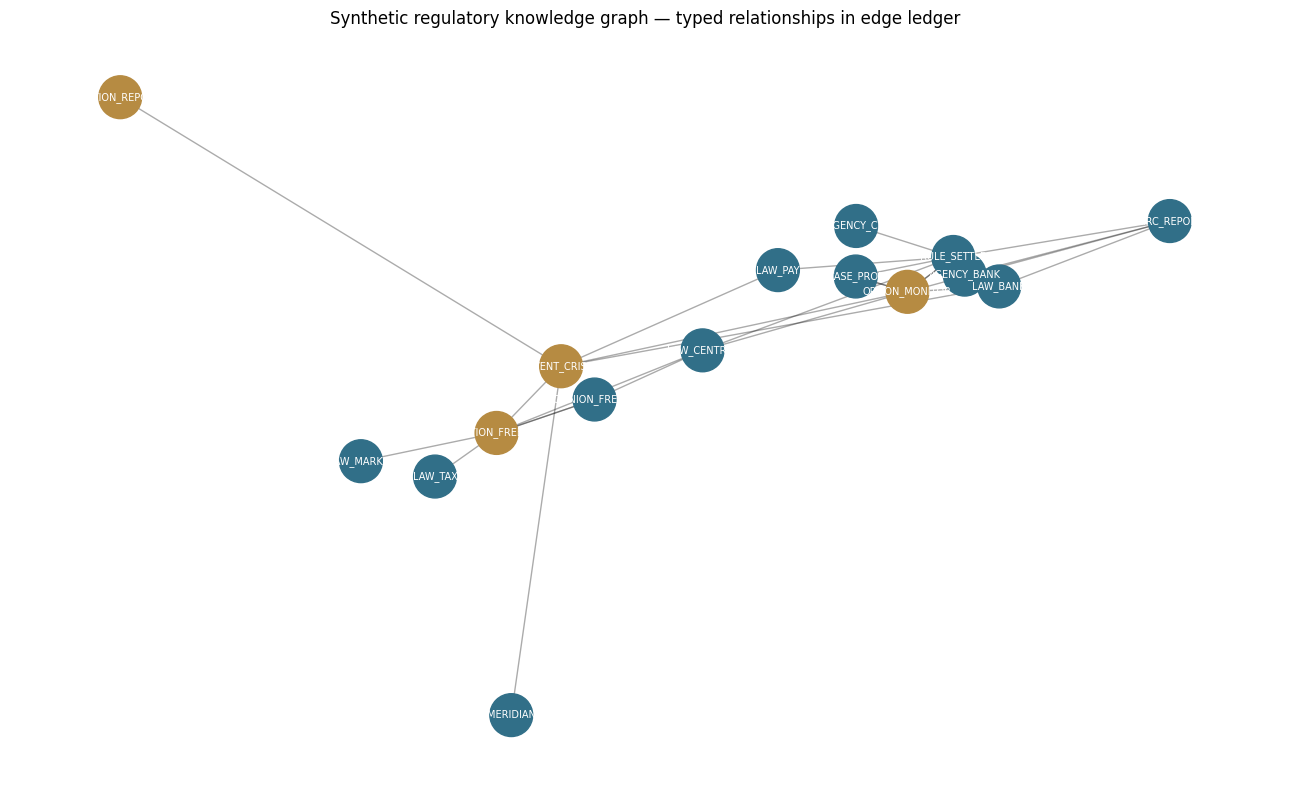

Validated: 16 nodes, 26 typed edges


In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# Re-establishing context to ensure cell independence
SYN='SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW'
raw=[
('LAW_PAY','statute','Fictional Payments Stability Act','Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.'),
('LAW_BANK','statute','Fictional Banking Coordination Act','Emergency obligations imposed on participating banks require prior consultation with the banking supervisor and a written coordination record.'),
('LAW_MARKET','statute','Fictional Securities Intermediaries Act','Securities intermediaries must preserve client-asset segregation and report material settlement exposure to the market supervisor.'),
('LAW_TAX','statute','Fictional Transaction Tax Continuity Act','Emergency payment controls do not suspend applicable tax reporting or authorize diversion of segregated customer funds.'),
('LAW_CENTRAL','statute','Fictional Central Bank Operations Act','The central bank may issue operational settlement instructions within its delegated mandate, but may not confiscate customer balances.'),
('RULE_SETTLE','secondary_rule','Fictional Settlement Continuity Rule','Enhanced monitoring and limited settlement safeguards require daily reporting, an expiration date, and public notice of customer-access protections.'),
('CIRC_REPORT','circular','Fictional Supervisory Circular 7','Affected banks and payment intermediaries must submit intraday liquidity and failed-settlement reports to their competent supervisors.'),
('CASE_PROP','judicial_interpretation','Fictional Proportionality Decision','An emergency restriction must be necessary, time-limited, reviewable, and no broader than needed to address the identified disruption.'),
('OPINION_FREEZE','interpretive_note','Fictional Customer Access Opinion','A blanket freeze of all customer balances conflicts with the customer-access safeguard and exceeds delegated operational authority.'),
('AGENCY_CB','institution','Fictional Central Bank','Competent authority for operational settlement continuity within the simulated legal framework.'),
('AGENCY_BANK','institution','Fictional Banking Supervisor','Competent supervisor for prudential obligations imposed on participating banks.'),
('MERIDIAN','entity','MeridianPay','Fictional payment intermediary affected by the simulated settlement incident.'),
('EVENT_CRISIS','event','MeridianPay Settlement Disruption','Synthetic settlement outage creates delayed payments and intraday liquidity pressures.'),
('OPTION_FREEZE','intervention','Blanket Balance Freeze','Candidate measure: freeze all customer balances across affected intermediaries.'),
('OPTION_MONITOR','intervention','Time-Limited Enhanced Monitoring','Candidate measure: 14-day monitoring, targeted settlement safeguard, daily reporting, and preserved customer access.'),
('OPTION_REPORT','intervention','Reporting-Only Response','Candidate measure: increase reporting but impose no temporary settlement safeguard.')]
records={i:{'id':i,'kind':kind,'title':title,'text':body,'provenance':SYN,'effective_from':'2026-01-01','effective_to':None} for i,kind,title,body in raw}

edges=[
('LAW_PAY','RULE_SETTLE','authorizes'),('LAW_CENTRAL','RULE_SETTLE','authorizes'),
('LAW_BANK','CIRC_REPORT','authorizes'),('RULE_SETTLE','CIRC_REPORT','implements'),
('CASE_PROP','RULE_SETTLE','constrains'),('LAW_CENTRAL','OPTION_FREEZE','constrains'),
('OPINION_FREEZE','OPTION_FREEZE','conflicts_with'),('LAW_TAX','OPTION_FREEZE','constrains'),
('LAW_MARKET','OPTION_FREEZE','constrains'),('RULE_SETTLE','OPTION_MONITOR','authorizes'),
('CASE_PROP','OPTION_MONITOR','constrains'),('LAW_BANK','OPTION_MONITOR','constrains'),
('AGENCY_CB','RULE_SETTLE','supervises'),('AGENCY_BANK','CIRC_REPORT','supervises'),
('EVENT_CRISIS','MERIDIAN','applies_to'),('EVENT_CRISIS','OPTION_MONITOR','triggered_by'),
('EVENT_CRISIS','OPTION_FREEZE','triggered_by'),('EVENT_CRISIS','OPTION_REPORT','triggered_by'),
('EVENT_CRISIS','LAW_PAY','applies_to'),('EVENT_CRISIS','LAW_BANK','applies_to'),
('OPTION_MONITOR','RULE_SETTLE','applies_to'),('OPTION_FREEZE','OPINION_FREEZE','conflicts_with'),
('OPTION_MONITOR','LAW_CENTRAL','applies_to'),('OPTION_MONITOR','CASE_PROP','applies_to'),
('OPTION_MONITOR','CIRC_REPORT','applies_to'),('OPINION_FREEZE','LAW_CENTRAL','interprets')]

allowed={'authorizes','constrains','implements','interprets','supervises','applies_to','triggered_by','conflicts_with'}
assert all(a in records and b in records and p in allowed for a,b,p in edges)
assert all(r['provenance']==SYN for r in records.values())
G=nx.MultiDiGraph()
for i,r in records.items():G.add_node(i,kind=r['kind'],title=r['title'])
for a,b,p in edges:G.add_edge(a,b,relation=p)
edge_df=pd.DataFrame(edges,columns=['source','target','predicate'])
edge_df.to_csv(OUT/'typed_edges.csv',index=False)
plt.figure(figsize=(13,8));pos=nx.spring_layout(G,seed=SEED)
colors=['#b68b42' if records[n]['kind'] in ('intervention','event') else '#316f88' for n in G.nodes]
nx.draw_networkx_nodes(G,pos,node_color=colors,node_size=950)
nx.draw_networkx_edges(G,pos,arrows=True,alpha=.33,arrowsize=12)
nx.draw_networkx_labels(G,pos,font_size=7,font_color='white')
plt.title('Synthetic regulatory knowledge graph — typed relationships in edge ledger');plt.axis('off');plt.tight_layout();plt.show()
print(f'Validated: {G.number_of_nodes()} nodes, {G.number_of_edges()} typed edges')

## 05 · Define the crisis and candidate interventions

A Second Brain becomes valuable when a specific decision creates a demand for context. In this cell, we formalize the crisis rather than asking a vague question about payment regulation. The fictional intermediary MeridianPay suffers a settlement interruption that creates liquidity stress for connected banks and merchants. The financial stability committee must propose a measure that reduces contagion, preserves lawful access to customer funds, respects supervisory competence, and can be implemented within a defined emergency window. These are decision criteria, not merely narrative details.

We create a crisis record with a timestamp, affected entities, immediate symptoms, and observable indicators. We also define three candidate interventions: blanket freezing of customer balances; enhanced settlement monitoring with a narrow liquidity safeguard; and a reporting-only response. The candidates are deliberately different in legal burden and operational intensity. A successful analysis must not assume that the most aggressive response is automatically the best response. It should identify both the source of authority and the constraints applicable to each option.

The notebook distinguishes event facts from legal propositions. A failed settlement batch is a synthetic fact about the simulated crisis; a restriction on customer-balance freezes is a synthetic rule within the exercise. This distinction is central to evidence governance. In a real deployment, event facts would come from telemetry, supervisory reporting, or authenticated incident records, while legal propositions would come from authoritative texts. They would have different update cycles, confidence measures, and responsible reviewers.

We then connect the crisis and policy options to the graph through typed edges. This step allows later retrieval to start from the actual decision mandate instead of searching the entire corpus with a generic natural-language query. The cell prints a compact crisis dashboard and intervention table. It does not yet choose a policy. Instead, it makes the decision problem explicit and supplies the anchors for graph traversal. The expected result is a reproducible scenario whose facts and objectives can be changed independently of the underlying knowledge architecture.

In [ ]:
import json
import pathlib
import pandas as pd
from IPython.display import display

# Re-establishing context to ensure cell independence
ROOT=pathlib.Path('/content/drive/MyDrive/Colab Notebooks/TOPIC_788 SECOND BRAIN PROJECT LAB 01')
OUT=ROOT/'outputs'
OUT.mkdir(parents=True,exist_ok=True)

crisis={'date':'2026-10-08','entity':'MERIDIAN','symptoms':['failed settlement batches','merchant payout delays','bank intraday liquidity pressure'],'mandate':'Contain propagation without violating delegated authority, customer access, or proportionality.','decision_horizon_days':14}
options={'OPTION_FREEZE':'Blanket freeze of customer balances','OPTION_MONITOR':'14-day enhanced monitoring, targeted safeguard, preserved access','OPTION_REPORT':'Reporting-only response'}
question=('MeridianPay has suffered a major settlement disruption. Recommend the legally defensible emergency response among the three candidate measures. '
          'Identify enabling authority, institutional coordination, proportionality, customer-access constraints, implementation steps, and unresolved questions. '
          'Use only supplied synthetic sources and cite source IDs.')
(OUT/'crisis.json').write_text(json.dumps({'crisis':crisis,'options':options},indent=2))
display(pd.DataFrame([{'option':k,'measure':v} for k,v in options.items()]));print('Decision mandate:',crisis['mandate'])

,option,measure
0,OPTION_FREEZE,Blanket freeze of customer balances
1,OPTION_MONITOR,"14-day enhanced monitoring, targeted safeguard..."
2,OPTION_REPORT,Reporting-only response


Decision mandate: Contain propagation without violating delegated authority, customer access, or proportionality.


## 06 · Baseline prompting and broad-context assembly

Before building sophisticated retrieval, we need credible baselines. A comparison that gives the graph method privileged evidence while starving the conventional LLM would teach the wrong lesson. The sixth cell therefore constructs two context packages. The baseline package contains only the crisis description, the candidate measures, and a generic request for a recommendation. The broad-context package contains the same decision question plus the text of every synthetic source in the corpus. Both packages are saved for later use, and their approximate lengths are reported.

The baseline represents the situation in which an analyst asks a capable conversational model to reason from the problem statement alone. Such a model may supply useful generic considerations, but it should not be expected to cite synthetic rules it has never seen. The long-context condition is more demanding. It gives the model access to all source texts and asks it to identify enabling provisions, limiting provisions, conflicts, and a defensible recommendation. In a small corpus, this condition may perform extremely well. That is not a failure of the experiment; it is evidence that graph construction may offer less advantage when all documents fit comfortably into context and the relevant dependencies are obvious.

We also calculate simple proxies for context cost, including character count and estimated token count. These are not exact provider billing measures. They help students understand that context engineering is partly a resource-allocation problem. A graph method that finds all decisive evidence but consumes more tokens and engineering effort than a clean long-context prompt may not be attractive for a one-off task. Conversely, its benefits may become compelling as the corpus grows, changes frequently, or requires reproducible evidence chains.

The cell does not call Claude yet. Separating package assembly from model inference makes it possible to inspect exactly what each method knows before judging its answer. This is a fundamental experimental discipline: evaluate retrieval quality independently of generation quality. The output is a pair of comparable context artifacts and a table describing their evidence exposure.

In [ ]:
import pandas as pd
import pathlib

# Re-establishing records context to ensure cell independence
SYN='SYNTHETIC EDUCATIONAL SOURCE — NOT ACTUAL LAW'
raw=[
('LAW_PAY','statute','Fictional Payments Stability Act','Temporary settlement safeguards may be ordered for a material disruption, subject to proportionality and a maximum initial period of 14 days.'),
('LAW_BANK','statute','Fictional Banking Coordination Act','Emergency obligations imposed on participating banks require prior consultation with the banking supervisor and a written coordination record.'),
('LAW_MARKET','statute','Fictional Securities Intermediaries Act','Securities intermediaries must preserve client-asset segregation and report material settlement exposure to the market supervisor.'),
('LAW_TAX','statute','Fictional Transaction Tax Continuity Act','Emergency payment controls do not suspend applicable tax reporting or authorize diversion of segregated customer funds.'),
('LAW_CENTRAL','statute','Fictional Central Bank Operations Act','The central bank may issue operational settlement instructions within its delegated mandate, but may not confiscate customer balances.'),
('RULE_SETTLE','secondary_rule','Fictional Settlement Continuity Rule','Enhanced monitoring and limited settlement safeguards require daily reporting, an expiration date, and public notice of customer-access protections.'),
('CIRC_REPORT','circular','Fictional Supervisory Circular 7','Affected banks and payment intermediaries must submit intraday liquidity and failed-settlement reports to their competent supervisors.'),
('CASE_PROP','judicial_interpretation','Fictional Proportionality Decision','An emergency restriction must be necessary, time-limited, reviewable, and no broader than needed to address the identified disruption.'),
('OPINION_FREEZE','interpretive_note','Fictional Customer Access Opinion','A blanket freeze of all customer balances conflicts with the customer-access safeguard and exceeds delegated operational authority.'),
('AGENCY_CB','institution','Fictional Central Bank','Competent authority for operational settlement continuity within the simulated legal framework.'),
('AGENCY_BANK','institution','Fictional Banking Supervisor','Competent supervisor for prudential obligations imposed on participating banks.'),
('MERIDIAN','entity','MeridianPay','Fictional payment intermediary affected by the simulated settlement incident.'),
('EVENT_CRISIS','event','MeridianPay Settlement Disruption','Synthetic settlement outage creates delayed payments and intraday liquidity pressures.'),
('OPTION_FREEZE','intervention','Blanket Balance Freeze','Candidate measure: freeze all customer balances across affected intermediaries.'),
('OPTION_MONITOR','intervention','Time-Limited Enhanced Monitoring','Candidate measure: 14-day monitoring, targeted settlement safeguard, daily reporting, and preserved customer access.'),
('OPTION_REPORT','intervention','Reporting-Only Response','Candidate measure: increase reporting but impose no temporary settlement safeguard.')]
records={i:{'id':i,'kind':kind,'title':title,'text':body,'provenance':SYN,'effective_from':'2026-01-01','effective_to':None} for i,kind,title,body in raw}

ROOT=pathlib.Path('/content/drive/MyDrive/Colab Notebooks/TOPIC_788 SECOND BRAIN PROJECT LAB 01')
OUT=ROOT/'outputs'

question=('MeridianPay has suffered a major settlement disruption. Recommend the legally defensible emergency response among the three candidate measures. '
          'Identify enabling authority, institutional coordination, proportionality, customer-access constraints, implementation steps, and unresolved questions. '
          'Use only supplied synthetic sources and cite source IDs.')

def source_excerpt(i):
    r=records[i];return f'[{i}] {r["title"]} ({r["kind"]}; SYNTHETIC): {r["text"]}'

source_ids=[i for i,r in records.items() if r['kind'] in {'statute','secondary_rule','circular','judicial_interpretation','interpretive_note'}]
contexts={}
contexts['A_problem_only']=question
contexts['B_long_context']=question+'\n\nALL SYNTHETIC SOURCES:\n'+'\n'.join(source_excerpt(i) for i in source_ids)
for k,v in contexts.items():(OUT/(k+'.txt')).write_text(v)
print(pd.DataFrame([{'strategy':k,'characters':len(v),'estimated_tokens':round(len(v)/4)} for k,v in contexts.items()]))

         strategy  characters  estimated_tokens
0  A_problem_only         351                88
1  B_long_context        2270               568


## 07 · Construct a transparent retrieval baseline

Retrieval-augmented generation is often discussed as though it were a single technique. In practice, it comprises several choices: how to chunk documents, how to represent a query, how to rank candidate passages, how many passages to return, and how to preserve citations. Our seventh cell implements a deliberately transparent baseline using TF-IDF vectors and cosine similarity. This is not a state-of-the-art semantic embedding system. It is a reproducible passage-retrieval comparator that students can understand and inspect without downloading a large embedding model or configuring an external service.

Each synthetic source is treated as one short passage. We vectorize the source text and compare it with a query describing the payment disruption and the committee's regulatory decision. The top-ranked passages are assembled into a retrieval context. The ranking is printed with scores and source identifiers, and the resulting package is saved. The pedagogical question is not whether TF-IDF is the best retrieval algorithm. It is whether similarity to the question reliably recovers the legal dependencies that matter to the decision.

A limitation of similarity retrieval is that decisive constraints may be phrased differently from the question. For example, a judicial note concerning proportionality or a tax rule governing segregation may be central even when its vocabulary overlaps weakly with the words settlement interruption. Retrieval may also overemphasize repeated terminology and underemphasize the hierarchy or direction of a legal relationship. These weaknesses motivate graph-aware context assembly, but they do not prove that vector RAG always fails. Strong embeddings, reranking, metadata filters, and hybrid retrieval can improve results substantially.

We therefore evaluate retrieval on a fixed set of instructor-defined critical evidence identifiers. This creates an explicit notion of evidence recall, separate from whether the model writes a persuasive memorandum. Students can change the query, increase the number of retrieved documents, or add a new synthetic source and observe how the ranking changes. The expected result is a clear, auditable retrieval baseline and a measured account of which crucial sources it includes or misses.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
texts=[records[i]['title']+' '+records[i]['text'] for i in source_ids]
vectorizer=TfidfVectorizer(ngram_range=(1,2),stop_words='english')
X=vectorizer.fit_transform(texts);q=vectorizer.transform([question])
scores=cosine_similarity(q,X).ravel()
ranking=sorted(zip(source_ids,scores),key=lambda t:(-t[1],t[0]))
TOP_K=5;rag_ids=[i for i,s in ranking[:TOP_K]]
contexts['C_tfidf_retrieval']=question+'\n\nRETRIEVED SYNTHETIC SOURCES:\n'+'\n'.join(source_excerpt(i) for i in rag_ids)
(OUT/'C_tfidf_retrieval.txt').write_text(contexts['C_tfidf_retrieval'])
display(pd.DataFrame([{'source_id':i,'similarity':round(float(s),3),'critical':i in critical} for i,s in ranking]))
print('TF-IDF critical-source recall:',round(len(critical.intersection(rag_ids))/len(critical),3))

,source_id,similarity,critical
0,OPINION_FREEZE,0.368,True
1,RULE_SETTLE,0.178,True
2,LAW_BANK,0.176,True
3,CASE_PROP,0.159,True
4,LAW_PAY,0.131,True
5,LAW_TAX,0.069,False
6,LAW_CENTRAL,0.053,True
7,CIRC_REPORT,0.026,False
8,LAW_MARKET,0.023,False


TF-IDF critical-source recall: 0.833


## 08 · Assemble context through typed graph traversal

The eighth cell implements the central architectural proposition of the series: context can be assembled by following meaningful relationships rather than relying solely on textual similarity. We begin at the crisis node and the candidate intervention nodes, traverse the typed graph within a bounded number of hops, and collect the source documents connected to those decision anchors. We then attach each source's text, document class, and a short path explanation showing why it was selected. The output is not simply a list of relevant passages; it is an evidence package that exposes the chain of reasoning used to retrieve them.

The traversal uses a bounded radius and deterministic ordering. Those constraints make the result reproducible and prevent a densely connected graph from expanding without limit. In larger systems, the same idea would require more sophisticated ranking based on edge type, temporal validity, authority, evidence quality, and task-specific relevance. A legal graph should not use popularity or centrality as a proxy for legal priority. For this first exercise, the typed edges and a small curated graph are sufficient to demonstrate the method without hiding the algorithm behind a complex infrastructure stack.

We explicitly include constraints and interpretations, not only authorizations. This is critical because a retrieval system optimized merely to find permission can produce dangerously one-sided advice. A defensible intervention requires an authority chain, an account of prohibitions, operational implementation conditions, and a statement of unresolved issues. The graph package therefore describes how each selected source bears on the committee's decision. It is formatted as ordinary text so it can be inspected independently of any LLM call.

The cell also compares the critical-source coverage and approximate context length of all four strategies. Students should interpret this comparison cautiously. The graph is hand-curated from the same synthetic corpus that defines the answer key, and this creates an educational advantage that would need to be controlled in real benchmarking. The purpose is to reveal the mechanism of structured context assembly, not to claim universal superiority. The expected result is a concise, provenance-aware package with explicit dependency paths.

In [ ]:
# Traverse undirected for discovery, but retain typed directed edges in the evidence report.
U=G.to_undirected()
anchors=['EVENT_CRISIS','OPTION_FREEZE','OPTION_MONITOR','OPTION_REPORT']
paths={}
for anchor in anchors:
    for target,path in nx.single_source_shortest_path(U,anchor,cutoff=3).items():
        if target in source_ids and (target not in paths or len(path)<len(paths[target])):paths[target]=path
graph_ids=sorted(paths,key=lambda i:(len(paths[i]),i))
context_lines=[]
for i in graph_ids:
    path=' -> '.join(paths[i]);context_lines.append(source_excerpt(i)+'\nRELEVANCE PATH: '+path)
contexts['D_graph_context']=question+'\n\nGRAPH-ASSEMBLED SYNTHETIC EVIDENCE:\n'+'\n\n'.join(context_lines)
(OUT/'D_graph_context.txt').write_text(contexts['D_graph_context'])
selected={'A_problem_only':[],'B_long_context':source_ids,'C_tfidf_retrieval':rag_ids,'D_graph_context':graph_ids}
summary=pd.DataFrame([{'strategy':k,'sources':len(selected[k]),'critical_recall':round(len(critical.intersection(selected[k]))/len(critical),3),'estimated_tokens':round(len(v)/4)} for k,v in contexts.items()])
display(summary);print('Graph-selected evidence:',graph_ids)

,strategy,sources,critical_recall,estimated_tokens
0,A_problem_only,0,0.000,88
1,B_long_context,9,1.000,568
2,D_graph_context,9,1.000,672
3,C_tfidf_retrieval,5,0.833,366


Graph-selected evidence: ['CASE_PROP', 'CIRC_REPORT', 'LAW_BANK', 'LAW_CENTRAL', 'LAW_MARKET', 'LAW_PAY', 'LAW_TAX', 'OPINION_FREEZE', 'RULE_SETTLE']


## 09 · Bounded judgment with Claude Haiku 5.5

The ninth cell introduces the language model as a judgment engine, but only after the knowledge architecture has produced inspectable evidence. The model is asked to evaluate the crisis, compare interventions, identify authority and constraints, and prepare a short decision memorandum. We use the same system instruction and response budget across context strategies so that differences are attributable as far as possible to the supplied evidence. A single response is not a statistically meaningful benchmark; it is a demonstration of a repeatable evaluation protocol.

Claude Haiku 5.5 is accessed through the Anthropic SDK using the exact model identifier claude-haiku-5-5. The Anthropic request omits the optional temperature argument entirely, allowing the provider default and avoiding SDK incompatibilities encountered in earlier notebook runs. The response budget is bounded to reduce truncation and cost. We request a plain-text memorandum with labeled sections rather than provider-enforced JSON schema. This reduces brittleness across model versions and allows us to retain a useful answer even when the model does not follow a rigid machine-readable template.

The API key is read from the Colab Secrets entry ANTHROPIC_API_KEY. If the secret is missing, the notebook does not fail. Instead, it displays a deterministic evidence diagnostic and explains that no model judgment was produced. If the service returns an error, the error is reported without exposing credentials. The code extracts text blocks defensively from the SDK response and records whether the reply appears to have been truncated. We avoid fabricating a model response, which would undermine the very evaluation discipline the laboratory seeks to teach.

The system prompt explicitly forbids claims about real-world law and instructs the model to cite synthetic note identifiers for legal propositions. It also requires an uncertainty section and a human-review gate before any operational action. The expected result, when the API is available, is a bounded analytical memorandum whose claims can be compared with the source package. Students should inspect omissions and unsupported statements rather than equating polished prose with legal validity.

In [ ]:
import importlib.util
if API_KEY and importlib.util.find_spec('anthropic') is None:
    subprocess.check_call([sys.executable,'-m','pip','-q','install','anthropic'])
SYSTEM=('You are a cautious financial-regulation analyst working ONLY with fictional synthetic documents. '
        'Never describe them as actual Mexican law. Cite synthetic source IDs for each legal claim. '
        'Use sections: Decision; Authority; Constraints; Implementation; Uncertainty; Human review. '
        'If evidence is absent, say so. Do not invent source IDs. Keep the memorandum concise.')
RUN_ALL_STRATEGIES=False  # Set True to compare all four Claude responses (uses more API credits).
responses={};status={}
def extract_text(message):
    return '\n'.join(getattr(block,'text','') for block in getattr(message,'content',[]) if getattr(block,'type','')=='text').strip()
if API_KEY:
    try:
        import anthropic
        client=anthropic.Anthropic(api_key=API_KEY,timeout=45.0,max_retries=1)
        names=list(contexts) if RUN_ALL_STRATEGIES else ['D_graph_context']
        for name in names:
            try:
                reply=client.messages.create(model=MODEL,max_tokens=MAX_TOKENS,
                    system=SYSTEM,messages=[{'role':'user','content':contexts[name]}])
                responses[name]=extract_text(reply)
                status[name]={'state':'model_response','stop_reason':getattr(reply,'stop_reason',None)}
                (OUT/(name+'_claude.txt')).write_text(responses[name],encoding='utf-8')
            except Exception as exc:
                status[name]={'state':'api_error','error_type':type(exc).__name__}
                print(name,'API unavailable:',type(exc).__name__,str(exc)[:180])
    except Exception as exc:
        print('Anthropic SDK initialization failed:',type(exc).__name__)
else:
    print('No ANTHROPIC_API_KEY found in Colab Secrets. No Claude judgment was generated.')
if responses:
    for name,answer in responses.items():
        print('\nMODEL JUDGMENT:',name,'\n',answer[:7500],'\nSTATUS:',status[name])
else:
    print('Deterministic evidence diagnostic only (NOT a model judgment):')
    print('Graph package covers',len(critical.intersection(graph_ids)),'of',len(critical),'instructor-defined critical source IDs.')


MODEL JUDGMENT: D_graph_context 
 ## Decision

**Recommended measure: OPTION_MONITOR**, meaning enhanced monitoring with limited, time-bounded settlement safeguards. It is the most defensible of the candidates in the supplied evidence, but this is a provisional recommendation.

- **Rejected: OPTION_FREEZE (blanket freeze of customer balances).** The evidence indicates it conflicts with the customer-access safeguard and exceeds delegated operational authority [OPINION_FREEZE]. It also cannot confiscate customer balances [LAW_CENTRAL] or divert segregated funds [LAW_TAX].
- **Third candidate: not identified.** The request refers to three candidate measures, but the supplied evidence addresses only two options (OPTION_MONITOR, OPTION_FREEZE) and an event pathway (EVENT_CRISIS). No source describes a third measure, so it cannot be assessed.

## Authority

- **Temporary safeguards:** The Payments Stability Act permits temporary settlement safeguards for a material disruption, subject to pr

## 10 · Evaluate, export, and define the next experiment

The final code cell closes the loop between knowledge construction and institutional learning. It computes transparent evidence metrics for each context strategy, saves all assembled packages, and exports the Obsidian vault together with the edge ledger, scenario, and evaluation report. The metrics include coverage of a predefined set of critical source identifiers, approximate context size, and a simple evidence-efficiency measure. These are diagnostics, not claims about the ultimate legal quality of a recommendation. A fully developed evaluation would require expert scoring of each generated memorandum for correctness, proportionality, legal hierarchy, and treatment of uncertainty.

The export is designed to be portable. A student can download the ZIP, extract it, and open the Vault directory in Obsidian. The Markdown notes remain readable without Obsidian, and the CSV edge ledger can be loaded into NetworkX or another graph database. This avoids making the teaching artifact dependent on a particular interface. The notebook also writes a manifest documenting the synthetic nature of the materials and the model configuration. No API key, credential, or provider response metadata containing secrets is included.

We finish with a reproducibility check: the exported ZIP is inspected for the expected files, and a compact evaluation table is displayed. The cell records which strategies actually received a model response. This distinction matters because evidence coverage can be evaluated without Claude, but generated judgment cannot. The laboratory should never present deterministic heuristics as though they were the output of the LLM. In an institutional setting, provenance must extend to the process that generated each conclusion, not just the documents cited by it.

The final exercise for students is a controlled counterfactual. Modify one synthetic constraint—for example, add a new approval requirement or change the effective date of a circular—then rerun the notebook. Observe whether the graph validation, retrieval packages, and model recommendation reflect the change. This turns the Second Brain from a static repository into an updateable decision-support system. The expected result is not a definitive regulatory opinion, but a complete educational prototype showing how structured knowledge can make context more explicit, reasoning more auditable, and institutional judgment more responsive to new evidence.

In [ ]:
import zipfile
report=[]
for name,ctx in contexts.items():
    ids=selected[name];recall=len(critical.intersection(ids))/len(critical)
    report.append({'strategy':name,'sources':len(ids),'critical_recall':round(recall,3),
                   'estimated_tokens':round(len(ctx)/4),'critical_sources_per_1k_tokens':round(len(critical.intersection(ids))/max(1,len(ctx)/4000),2),
                   'claude_status':status.get(name,{}).get('state','not_run')})
metrics=pd.DataFrame(report);metrics.to_csv(OUT/'evaluation.csv',index=False)
manifest={'project':'Second Brain Lab 01','synthetic':True,'model':MODEL,'temperature':'provider_default (omitted from request)',
          'max_tokens':MAX_TOKENS,'critical_evidence_ids':sorted(critical),'notes':len(records),
          'edges':len(edges),'warning':'Synthetic teaching exercise; not a statement of actual law.'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2))
zip_path=ROOT/'Second_Brain_Lab01_Obsidian_Vault_and_Results.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(VAULT.rglob('*')):
        if p.is_file():z.write(p,p.relative_to(ROOT))
    for p in sorted(OUT.rglob('*')):
        if p.is_file():z.write(p,p.relative_to(ROOT))
with zipfile.ZipFile(zip_path) as z:
    assert z.testzip() is None
    assert 'Vault/START_HERE.md' in z.namelist()
display(metrics)
print('Exported:',zip_path,'bytes:',zip_path.stat().st_size)
try:
    from google.colab import files
    print('To download, run: files.download(str(zip_path))')
except ImportError: pass

,strategy,sources,critical_recall,estimated_tokens,critical_sources_per_1k_tokens,claude_status
0,A_problem_only,0,0.000,88,0.0,not_run
1,B_long_context,9,1.000,568,6.0,not_run
2,D_graph_context,9,1.000,672,6.0,model_response
3,C_tfidf_retrieval,5,0.833,366,5.0,not_run


Exported: /content/drive/MyDrive/Colab Notebooks/TOPIC_788 SECOND BRAIN PROJECT LAB 01/Second_Brain_Lab01_Obsidian_Vault_and_Results.zip bytes: 13180
To download, run: files.download(str(zip_path))


## Conclusion — From document collections to auditable regulatory context

The first laboratory has constructed a small but complete knowledge-engineering system. It began with a fictional legal corpus, transformed each source into an Obsidian-compatible Markdown note, established typed relationships among sources and institutions, represented a payment-system crisis as a decision problem, and generated alternative context packages for an LLM judgment engine. The result is not a legal opinion and does not purport to interpret actual Mexican legislation. It is a reproducible demonstration of the architecture required to turn fragmented information into evidence that can support a disciplined institutional decision.

The most important conceptual lesson is that context is not equivalent to document volume. An analyst may possess every relevant statute and circular without recognizing that a narrow power in one source is conditioned by a consultation requirement in another, or that an apparently convenient intervention conflicts with a higher-level safeguard. The knowledge graph makes those dependencies explicit. It does not create authority, determine the correct interpretation by itself, or remove ambiguity. It provides a structured representation of where the analyst should look and why particular documents belong together.

The Obsidian-compatible vault demonstrates that this structure can remain human-readable. Notes are ordinary Markdown files. Their frontmatter provides identifiers and provenance, while wikilinks support navigation and inspection. The typed-edge ledger adds the semantics needed for computation. This distinction is central to a robust Second Brain. A visual network of connected notes can be useful for exploration, but the meaning of a legal relationship cannot be inferred from the existence of a line alone. Predicates such as authorizes, constrains, implements, and interprets must be maintained with the same care as the source texts themselves.

The experimental comparison also provides a methodological warning. A baseline LLM with no legal documents cannot reasonably be expected to recover fictional clauses. A long-context model may do very well when the corpus is small and carefully prepared. A lexical or vector retrieval system can be efficient, but its ranking may overlook a constraint that uses different language from the query. A graph-aware method can deliberately follow dependencies and produce an evidence trail, but its performance depends on graph completeness, correct edge semantics, and timely maintenance. No architecture should be declared superior solely because it performs well on a corpus designed by its own author.

For that reason, the notebook evaluates evidence exposure independently of model-generated prose. Critical-source recall is an informative but limited metric. It measures whether decisive sources appear in the context package, not whether the model understands their hierarchy, correctly applies proportionality, or proposes an operationally feasible response. A more demanding evaluation would use blinded expert reviewers, multiple synthetic scenarios, adversarial changes to the corpus, repeated model runs, and scoring rubrics that distinguish factual accuracy, legal consistency, traceability, and decision quality. Such a benchmark would also include stronger hybrid and semantic retrieval systems, rather than treating TF-IDF as representative of all RAG architectures.

The optional Claude Haiku 5.5 stage illustrates a practical separation of responsibilities. The model is asked to synthesize and judge; it is not allowed to silently manufacture sources. The program supplies the context, records which evidence was retrieved, bounds the response, and makes failure visible. Missing credentials, provider errors, and truncated answers are not concealed behind invented output. Human review remains essential because a model-generated memorandum can be articulate while misunderstanding an exception or overstating a delegated power. In a genuine regulatory environment, qualified counsel and responsible authorities must authenticate the materials, determine applicable law, and approve any intervention.

The most valuable follow-up experiment is to change the knowledge base and rerun the system. Add a fictional approval requirement, alter the effective date of a rule, or create a contradictory judicial interpretation. Observe whether graph validation detects a structural issue, whether retrieval still finds the critical evidence, and whether the recommendation changes for an intelligible reason. This is the beginning of institutional learning: a Second Brain is not a static archive but a maintained representation of evolving knowledge and its implications for action.

The next laboratory will apply the same architecture to trading and market contagion. There, edges will represent economic exposure rather than legal authority, and updates will arrive through events rather than new legal instruments. The comparison will shift from legal consistency to the speed and quality of risk detection. Yet the underlying intellectual sequence will remain the same: represent knowledge, identify meaningful relationships, assemble decision-relevant context, exercise bounded judgment, and preserve an audit trail. Across all four laboratories, that sequence is the bridge from information abundance to contextual intelligence.